#Import Modules

In [49]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [50]:
df = pd.read_csv('Housing.csv')
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


#Data Exploration

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [52]:
df.isnull().sum()

,0
price,0
area,0
bedrooms,0
bathrooms,0
stories,0
mainroad,0
guestroom,0
basement,0
hotwaterheating,0
airconditioning,0


In [53]:
df.duplicated().sum()

np.int64(0)

In [54]:
df.describe()

,price,area,bedrooms,bathrooms,stories,parking
count,5.450000e+02,545.000000,545.000000,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,2.965138,1.286239,1.805505,0.693578
std,1.870440e+06,2170.141023,0.738064,0.502470,0.867492,0.861586
min,1.750000e+06,1650.000000,1.000000,1.000000,1.000000,0.000000
25%,3.430000e+06,3600.000000,2.000000,1.000000,1.000000,0.000000
50%,4.340000e+06,4600.000000,3.000000,1.000000,2.000000,0.000000
75%,5.740000e+06,6360.000000,3.000000,2.000000,2.000000,1.000000
max,1.330000e+07,16200.000000,6.000000,4.000000,4.000000,3.000000


In [55]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


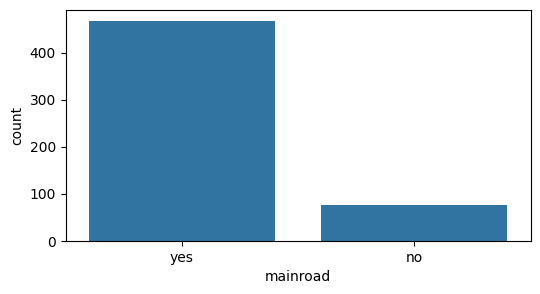

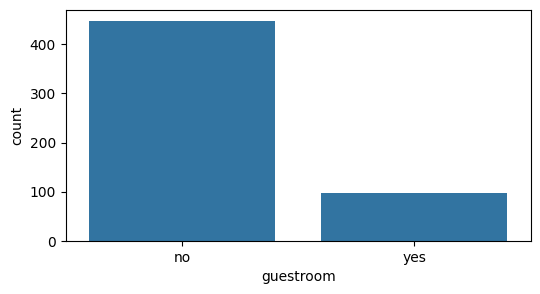

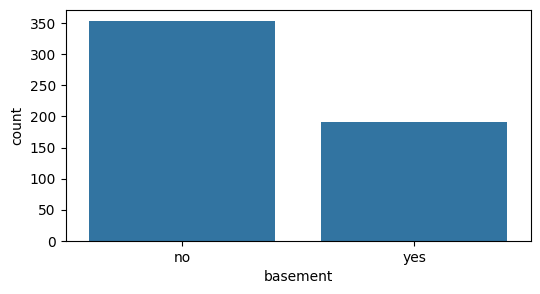

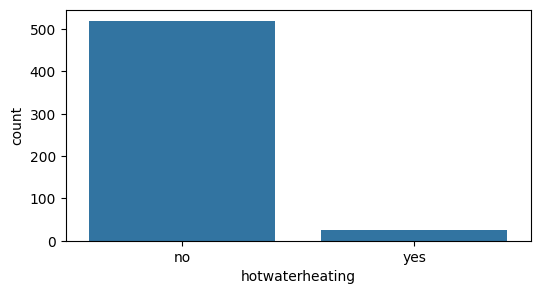

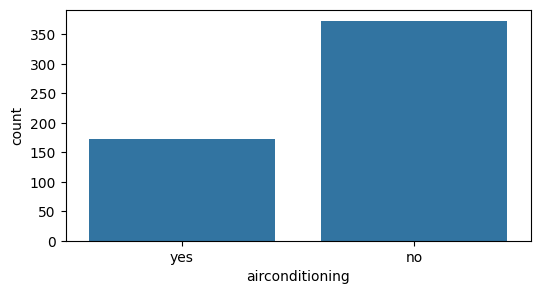

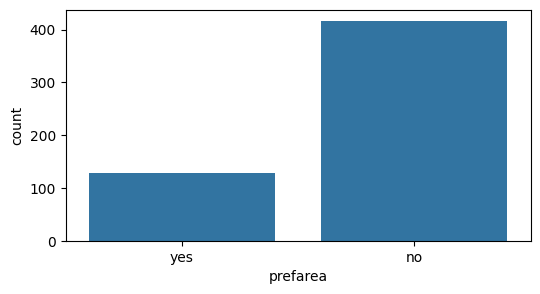

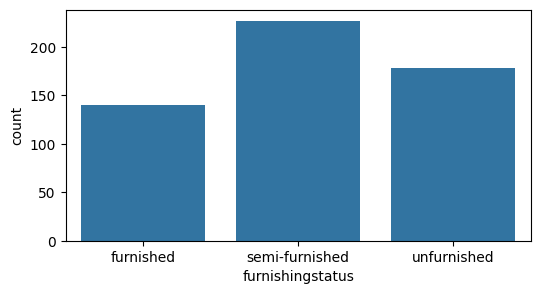

In [56]:
cat_col= [ 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
num_col= ['stories', 'bathrooms','bedrooms', 'parking', 'area', 'price']

for i in cat_col:
  plt.figure(figsize= (6,3))
  sns.countplot(x= df[i])

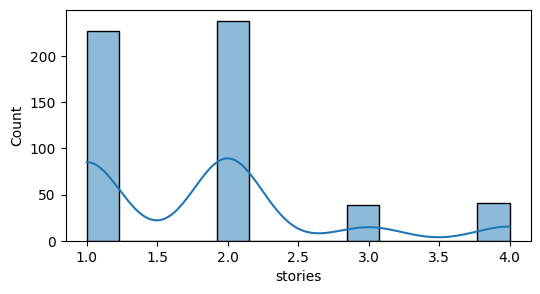

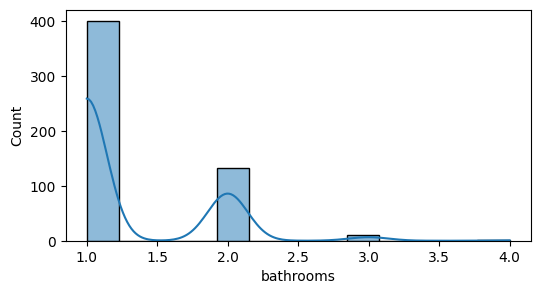

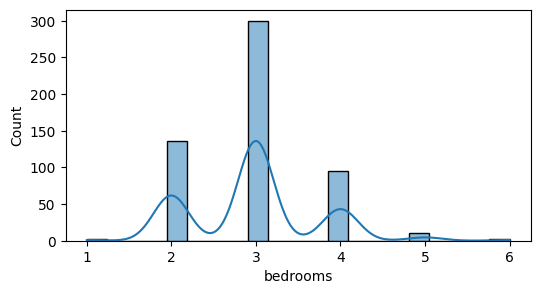

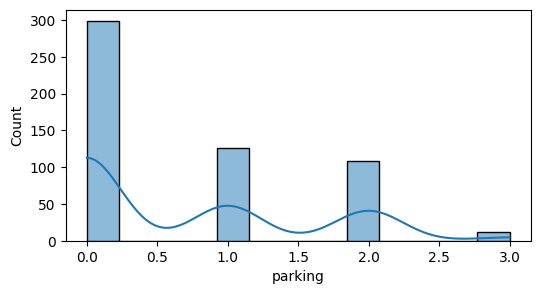

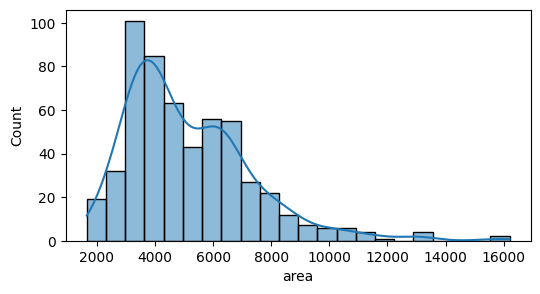

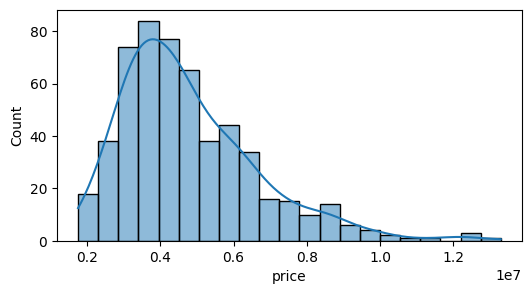

In [57]:
for i in num_col:
  plt.figure(figsize= (6,3))
  sns.histplot(df[i], kde= True)

In [58]:
df= df.drop('hotwaterheating',axis=1)
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,0,no,furnished


<Axes: >

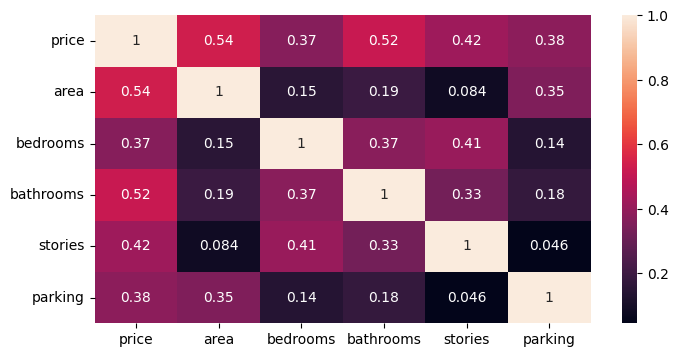

In [59]:
plt.figure(figsize= (8,4))
sns.heatmap(df.corr(numeric_only=True),annot= True)

#Data Cleaning and Preprocessing

In [60]:
df2= df.copy()

In [61]:
df2.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,yes,2,no,furnished


In [62]:
df2.shape

(545, 12)

In [63]:
df2.drop_duplicates(inplace=True)
df2.shape

(545, 12)

In [64]:
df.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus'],
      dtype='object')

In [65]:
des_cols= ['mainroad', 'guestroom', 'basement', 'airconditioning','prefarea']

In [66]:
for i in range(len(des_cols)):
    print("\n")
    print(df[des_cols[i]].value_counts())



mainroad
yes    468
no      77
Name: count, dtype: int64


guestroom
no     448
yes     97
Name: count, dtype: int64


basement
no     354
yes    191
Name: count, dtype: int64


airconditioning
no     373
yes    172
Name: count, dtype: int64


prefarea
no     417
yes    128
Name: count, dtype: int64


In [67]:
for col in des_cols:
  df2[col]= df2[col].map({
      'yes':1,
      'no': 0
  })

In [68]:
df2.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,1,2,0,furnished


In [69]:
df2= pd.get_dummies(df2, columns= ['furnishingstatus'])
df2

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,1,2,1,True,False,False
1,12250000,8960,4,4,4,1,0,0,1,3,0,True,False,False
2,12250000,9960,3,2,2,1,0,1,0,2,1,False,True,False
3,12215000,7500,4,2,2,1,0,1,1,3,1,True,False,False
4,11410000,7420,4,1,2,1,1,1,1,2,0,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,1,0,1,0,2,0,False,False,True
541,1767150,2400,3,1,1,0,0,0,0,0,0,False,True,False
542,1750000,3620,2,1,1,1,0,0,0,0,0,False,False,True
543,1750000,2910,3,1,1,0,0,0,0,0,0,True,False,False


In [70]:
df2= df2.astype(int)
df2.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,1,2,1,1,0,0
1,12250000,8960,4,4,4,1,0,0,1,3,0,1,0,0
2,12250000,9960,3,2,2,1,0,1,0,2,1,0,1,0
3,12215000,7500,4,2,2,1,0,1,1,3,1,1,0,0
4,11410000,7420,4,1,2,1,1,1,1,2,0,1,0,0


In [71]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 14 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   price                            545 non-null    int64
 1   area                             545 non-null    int64
 2   bedrooms                         545 non-null    int64
 3   bathrooms                        545 non-null    int64
 4   stories                          545 non-null    int64
 5   mainroad                         545 non-null    int64
 6   guestroom                        545 non-null    int64
 7   basement                         545 non-null    int64
 8   airconditioning                  545 non-null    int64
 9   parking                          545 non-null    int64
 10  prefarea                         545 non-null    int64
 11  furnishingstatus_furnished       545 non-null    int64
 12  furnishingstatus_semi-furnished  545 non-null    i

#Feature Engineering

In [72]:
from scipy.stats import pearsonr

In [73]:
df2.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,airconditioning,parking,prefarea,furnishingstatus_furnished,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,1,2,1,1,0,0
1,12250000,8960,4,4,4,1,0,0,1,3,0,1,0,0
2,12250000,9960,3,2,2,1,0,1,0,2,1,0,1,0
3,12215000,7500,4,2,2,1,0,1,1,3,1,1,0,0
4,11410000,7420,4,1,2,1,1,1,1,2,0,1,0,0


In [74]:
df2.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus_furnished', 'furnishingstatus_semi-furnished',
       'furnishingstatus_unfurnished'],
      dtype='object')

In [75]:
#Pearson correlation Numerical vs Price
num_features = ['area','bedrooms','bathrooms','stories','parking']

correlations= {
    feature : pearsonr(df2[feature], df2['price'])[0]
    for feature in num_features

}

correlations_df = pd.DataFrame(list(correlations.items()), columns=['Feature', 'Correlation'])
correlations_df.sort_values(by='Correlation', ascending=False)


,Feature,Correlation
0,area,0.535997
2,bathrooms,0.517545
3,stories,0.420712
4,parking,0.384394
1,bedrooms,0.366494


In [76]:
cat_features = [
    'mainroad',
    'guestroom',
    'basement',
    'airconditioning',
    'prefarea',
    'furnishingstatus_furnished',
    'furnishingstatus_semi-furnished',
    'furnishingstatus_unfurnished'
]

In [77]:
#Chi-Square for categorical vs price

from scipy.stats import chi2_contingency
alpha = 0.05

df2['price_bin2']= pd.qcut(df2['price'], q= 4, labels= False)

chi2_results= {}
for col in cat_features:
    contingency= pd.crosstab(df2[col], df2['price'])
    chi2, p_val, _, _= chi2_contingency(contingency)
    decisions= 'Reject the null hypothesis' if p_val < alpha else 'Fail to reject the null hypothesis'
    chi2_results[col]= {'chi2_statistic': chi2, 'p_value': p_val, 'decision': decisions}

chi2_df= pd.DataFrame(chi2_results).T
chi2_df= chi2_df.sort_values(by= 'p_value')
chi2_df

,chi2_statistic,p_value,decision
guestroom,302.301245,0.000136,Reject the null hypothesis
prefarea,292.690557,0.000546,Reject the null hypothesis
airconditioning,290.70048,0.000718,Reject the null hypothesis
furnishingstatus_unfurnished,278.300644,0.003583,Reject the null hypothesis
basement,264.630556,0.01689,Reject the null hypothesis
furnishingstatus_furnished,247.397465,0.083679,Fail to reject the null hypothesis
mainroad,243.542131,0.113115,Fail to reject the null hypothesis
furnishingstatus_semi-furnished,236.230501,0.189001,Fail to reject the null hypothesis


In [78]:
for col in cat_features:

    contingency = pd.crosstab(
        df2[col],
        df2['price_bin2']
    )

    chi2, p, _, _ = chi2_contingency(contingency)

    n = contingency.to_numpy().sum()
    r, k = contingency.shape

    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    )

    print(col, "Cramer's V:", round(cramers_v, 3))

mainroad Cramer's V: 0.349
guestroom Cramer's V: 0.308
basement Cramer's V: 0.241
airconditioning Cramer's V: 0.448
prefarea Cramer's V: 0.345
furnishingstatus_furnished Cramer's V: 0.225
furnishingstatus_semi-furnished Cramer's V: 0.305
furnishingstatus_unfurnished Cramer's V: 0.414


In [79]:
df_final= df2.drop(['furnishingstatus_furnished','price_bin2'],axis=1)
df_final.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,1,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,1,2,0,0,0


#Model Traning

In [80]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [81]:
X= df_final.drop('price',axis=1)
Y= df_final['price']

In [82]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.33, random_state=42)

In [83]:
scaler= StandardScaler()

In [84]:
X_train_scaled= scaler.fit_transform(X_train)
X_test_scaled= scaler.transform(X_test)

In [85]:
models= {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor()
}

In [86]:
results= []

for name, model in models.items():
  model.fit(X_train_scaled, y_train)

  y_pred= model.predict(X_test_scaled)

  mae= mean_absolute_error(y_test, y_pred)
  mse= mean_squared_error(y_test, y_pred)
  rmse= np.sqrt(mse)
  r2= r2_score(y_test, y_pred)

  results.append({
      'Model': name,
      'MAE': mae,
      'MSE': mse,
      'RMSE': rmse,
      'R2 Score': r2
  })

results_df= pd.DataFrame(results)

results_df= results_df.sort_values(
    by= 'R2 Score',
    ascending= False
)

print(results_df)

               Model            MAE           MSE          RMSE  R2 Score
0  Linear Regression  922767.685693  1.513225e+12  1.230132e+06  0.646915
1                KNN  912124.500000  1.583887e+12  1.258526e+06  0.630427


In [87]:
ns_models= {
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor()
}

In [88]:


for name, model in ns_models.items():
  model.fit(X_train, y_train)

  y_pred= model.predict(X_test)

  mae= mean_absolute_error(y_test, y_pred)
  mse= mean_squared_error(y_test, y_pred)
  rmse= np.sqrt(mse)
  r2= r2_score(y_test, y_pred)

  results.append({
      'Model': name,
      'MAE': mae,
      'MSE': mse,
      'RMSE': rmse,
      'R2 Score': r2
  })

results_df= pd.DataFrame(results)

results_df= results_df.sort_values(
    by= 'R2 Score',
    ascending= False
)

print(results_df)

               Model           MAE           MSE          RMSE  R2 Score
0  Linear Regression  9.227677e+05  1.513225e+12  1.230132e+06  0.646915
4  Gradient Boosting  9.172877e+05  1.558733e+12  1.248492e+06  0.636296
1                KNN  9.121245e+05  1.583887e+12  1.258526e+06  0.630427
3      Random Forest  9.666626e+05  1.848274e+12  1.359512e+06  0.568736
2      Decision Tree  1.203380e+06  3.082714e+12  1.755766e+06  0.280701


#Model Fixing


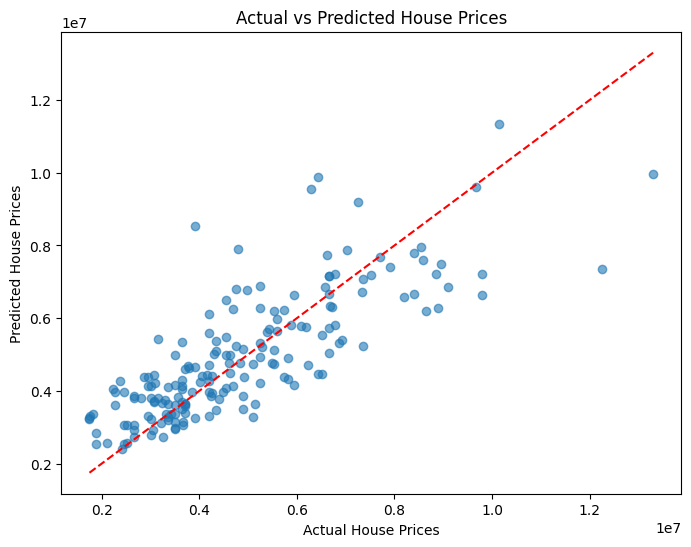

In [89]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [90]:
comparison = pd.DataFrame({
    'Actual Price': y_test,
    'Predicted Price': y_pred
})

comparison['Error'] = (
    comparison['Actual Price'] -
    comparison['Predicted Price']
)

comparison['Absolute Error'] = abs(comparison['Error'])

comparison['Percentage Error'] = (
    comparison['Absolute Error'] /
    comparison['Actual Price']
) * 100

print(comparison.head(10))

     Actual Price  Predicted Price         Error  Absolute Error  \
316       4060000     4.411677e+06 -3.516768e+05    3.516768e+05   
77        6650000     7.170181e+06 -5.201815e+05    5.201815e+05   
360       3710000     3.635883e+06  7.411661e+04    7.411661e+04   
90        6440000     4.456083e+06  1.983917e+06    1.983917e+06   
493       2800000     3.814847e+06 -1.014847e+06    1.014847e+06   
209       4900000     3.869311e+06  1.030689e+06    1.030689e+06   
176       5250000     5.315563e+06 -6.556290e+04    6.556290e+04   
249       4543000     5.474840e+06 -9.318401e+05    9.318401e+05   
516       2450000     3.051636e+06 -6.016359e+05    6.016359e+05   
426       3353000     3.282788e+06  7.021173e+04    7.021173e+04   

     Percentage Error  
316          8.661990  
77           7.822278  
360          1.997752  
90          30.806170  
493         36.244546  
209         21.034478  
176          1.248817  
249         20.511558  
516         24.556569  
426        

In [91]:
worst_predictions = comparison.sort_values(
    by='Absolute Error',
    ascending=False
)

print(worst_predictions.head(10))

     Actual Price  Predicted Price         Error  Absolute Error  \
2        12250000     7.342335e+06  4.907665e+06    4.907665e+06   
331       3920000     8.546839e+06 -4.626839e+06    4.626839e+06   
89        6440000     9.877838e+06 -3.437838e+06    3.437838e+06   
0        13300000     9.953707e+06  3.346293e+06    3.346293e+06   
93        6300000     9.549045e+06 -3.249045e+06    3.249045e+06   
10        9800000     6.631304e+06  3.168696e+06    3.168696e+06   
220       4795000     7.905087e+06 -3.110087e+06    3.110087e+06   
18        8890000     6.291170e+06  2.598830e+06    2.598830e+06   
9         9800000     7.209572e+06  2.590428e+06    2.590428e+06   
22        8645000     6.207917e+06  2.437083e+06    2.437083e+06   

     Percentage Error  
2           40.062568  
331        118.031612  
89          53.382582  
0           25.160096  
93          51.572148  
10          32.333631  
220         64.861047  
18          29.233184  
9           26.432936  
22         

In [92]:
comparison['Price Category'] = pd.cut(
    comparison['Actual Price'],
    bins=[0, 3000000, 5000000, 8000000, float('inf')],
    labels=['Budget', 'Mid-range', 'Premium', 'Luxury']
)

In [93]:
error_analysis = comparison.groupby(
    'Price Category',
    observed=False
).agg(
    Average_Actual=('Actual Price', 'mean'),
    Average_Predicted=('Predicted Price', 'mean'),
    MAE=('Absolute Error', 'mean'),
    MAPE=('Percentage Error', 'mean')
)

print(error_analysis)

                Average_Actual  Average_Predicted           MAE       MAPE
Price Category                                                            
Budget            2.396969e+06       3.371771e+06  9.748028e+05  43.152554
Mid-range         3.897542e+06       4.278297e+06  6.969031e+05  17.805405
Premium           6.212302e+06       5.960732e+06  9.253091e+05  14.966654
Luxury            9.471000e+06       7.670534e+06  1.950679e+06  19.974654


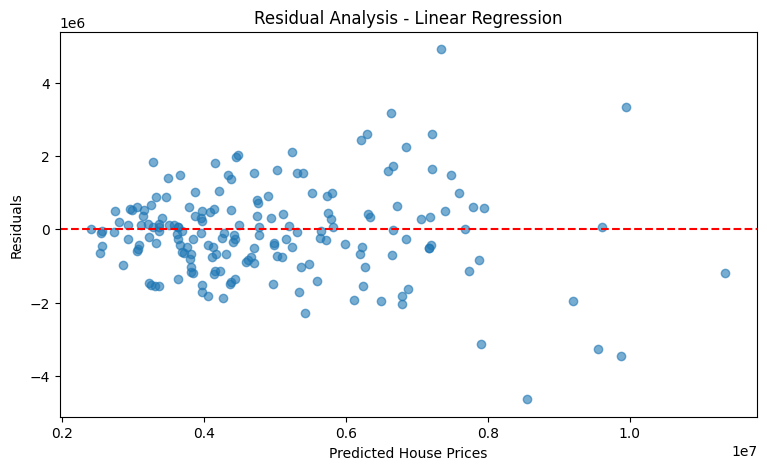

In [94]:
plt.figure(figsize=(9, 5))

plt.scatter(
    y_pred,
    comparison['Error'],
    alpha=0.6
)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted House Prices")
plt.ylabel("Residuals")
plt.title("Residual Analysis - Linear Regression")

plt.show()